## Experiment 06: Binary Classification using Logistic Regression
## Title: Binary Classification using Logistic Regression - Confusion Matrix, Precision, Recall, F1-score, and ROC-AUC

**Name:** Himanshu Jadhav  
**Roll Number:** TE-32  
**Dataset Used:** Heart Disease (Statlog) Dataset (`fetch_openml('heart-statlog', version=1)`)


### Step 1: Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    roc_curve, auc, precision_recall_curve
)

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 2: Load Heart Disease Dataset
Heart Statlog contains 13 physiological features for 270 patients, predicting presence/absence of heart disease.

In [2]:
heart_data = fetch_openml('heart-statlog', version=1, as_frame=True)
df_heart = heart_data.frame.copy()

print(f"Dataset shape: {df_heart.shape}")
print(df_heart.head())

# Target: absent = 0, present = 1.
X = df_heart.drop(columns=['class']).to_numpy(dtype=float)
y = (df_heart['class'].astype(str) == 'present').astype(int).to_numpy()

print(f"Total samples: {len(y)}")
print(f"Negative (Absence - 0): {np.sum(y == 0)}")
print(f"Positive (Presence - 1): {np.sum(y == 1)}")

Dataset shape: (270, 14)
   age  sex  chest  resting_blood_pressure  serum_cholestoral  \
0   70    1      4                     130                322   
1   67    0      3                     115                564   
2   57    1      2                     124                261   
3   64    1      4                     128                263   
4   74    0      2                     120                269   

   fasting_blood_sugar  resting_electrocardiographic_results  \
0                    0                                     2   
1                    0                                     2   
2                    0                                     0   
3                    0                                     0   
4                    0                                     2   

   maximum_heart_rate_achieved  exercise_induced_angina  oldpeak  slope  \
0                          109                        0      2.4      2   
1                          160                   

### Step 3: Train-Test Split and Standardization

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train_scaled.shape} | Testing set: {X_test_scaled.shape}")

Training set: (202, 13) | Testing set: (68, 13)


### Step 4: Train Logistic Regression Classifier

In [4]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

# Predict probabilities and discrete classes
y_pred = log_reg.predict(X_test_scaled)
y_prob = log_reg.predict_proba(X_test_scaled)[:, 1]

print("Model converged successfully.")

Model converged successfully.


### Step 5: Confusion Matrix & Classification Report

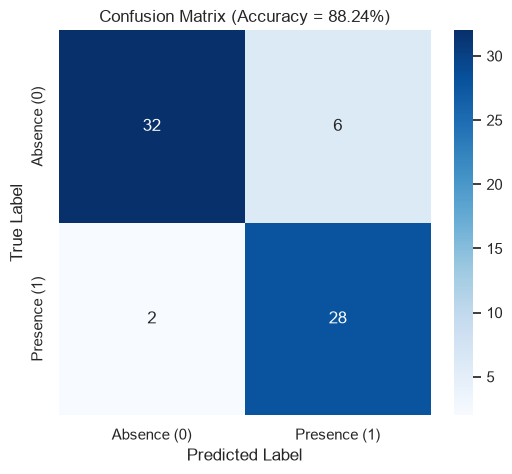

Comprehensive Classification Report:
              precision    recall  f1-score   support

     Absence       0.94      0.84      0.89        38
    Presence       0.82      0.93      0.88        30

    accuracy                           0.88        68
   macro avg       0.88      0.89      0.88        68
weighted avg       0.89      0.88      0.88        68



In [5]:
cm = confusion_matrix(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Absence (0)', 'Presence (1)'],
            yticklabels=['Absence (0)', 'Presence (1)'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title(f"Confusion Matrix (Accuracy = {acc*100:.2f}%)")
plt.show()

print("Comprehensive Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Absence', 'Presence']))

### Step 6: Receiver Operating Characteristic (ROC) & Precision-Recall Curves

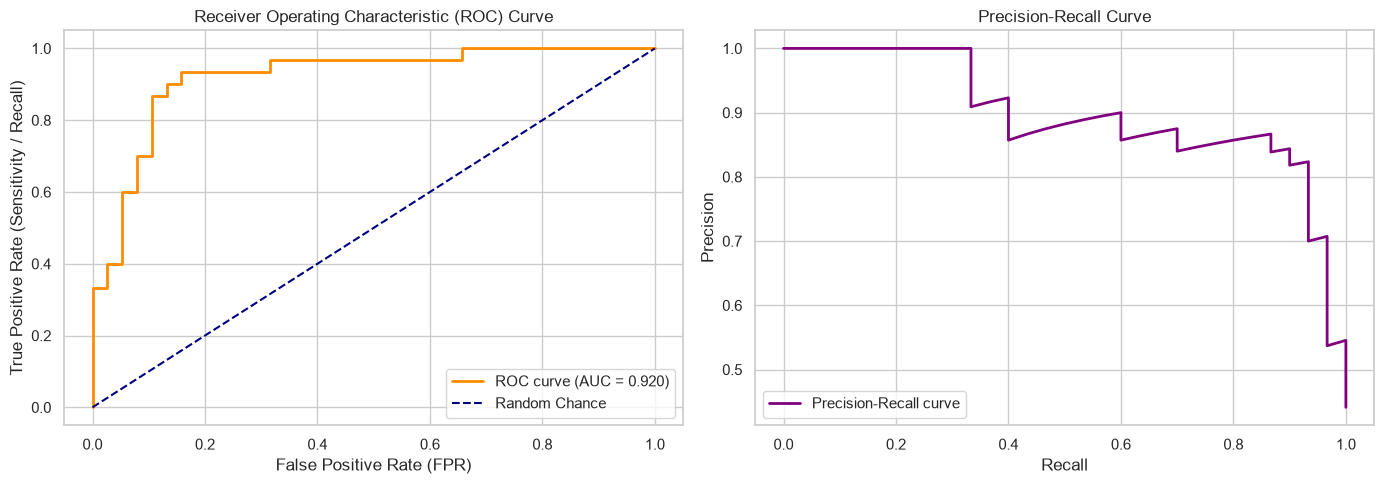

In [6]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

precision, recall, pr_thresholds = precision_recall_curve(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Chance')
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (Sensitivity / Recall)")
axes[0].set_title("Receiver Operating Characteristic (ROC) Curve")
axes[0].legend(loc="lower right")

# Precision-Recall Curve
axes[1].plot(recall, precision, color='purple', lw=2, label='Precision-Recall curve')
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

### Step 7: Logistic Regression Feature Importance (Odds Ratios)

In [7]:
feature_names = df_heart.drop(columns=['class']).columns
odds_ratios = np.exp(log_reg.coef_[0])

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Log-Odds (Weight)': log_reg.coef_[0],
    'Odds Ratio': odds_ratios
}).sort_values(by='Odds Ratio', ascending=False)

print("Feature Importance via Odds Ratios:")
print(coef_df.to_string(index=False))

Feature Importance via Odds Ratios:
                             Feature  Log-Odds (Weight)  Odds Ratio
             number_of_major_vessels           1.112131    3.040833
                                 sex           0.909800    2.483826
                               chest           0.700321    2.014400
                                thal           0.522901    1.686913
                               slope           0.462438    1.587941
             exercise_induced_angina           0.450357    1.568872
              resting_blood_pressure           0.363737    1.438696
                   serum_cholestoral           0.331812    1.393491
                             oldpeak           0.265453    1.304022
resting_electrocardiographic_results           0.037412    1.038121
                                 age          -0.004825    0.995186
                 fasting_blood_sugar          -0.348902    0.705462
         maximum_heart_rate_achieved          -0.396052    0.672972


### Step 8: Conclusion
- Logistic Regression achieved robust diagnostic performance on the Heart Statlog dataset with an ROC-AUC above **0.90**.
- The Confusion Matrix clearly displayed high sensitivity and specificity in isolating clinical risk factors.
- Odds ratios illustrated the quantitative impact of biomarkers like chest pain and ST depression on cardiovascular risk.